#### Building an Automated Guessing Game using LangGraph

Importing StateGraph from langgraph.graph is necessary to build stateful, graph-based workflows in LangGraph. This is a core component for creating complex AI agents and applications that require shared, persistent memory and conditional logic.

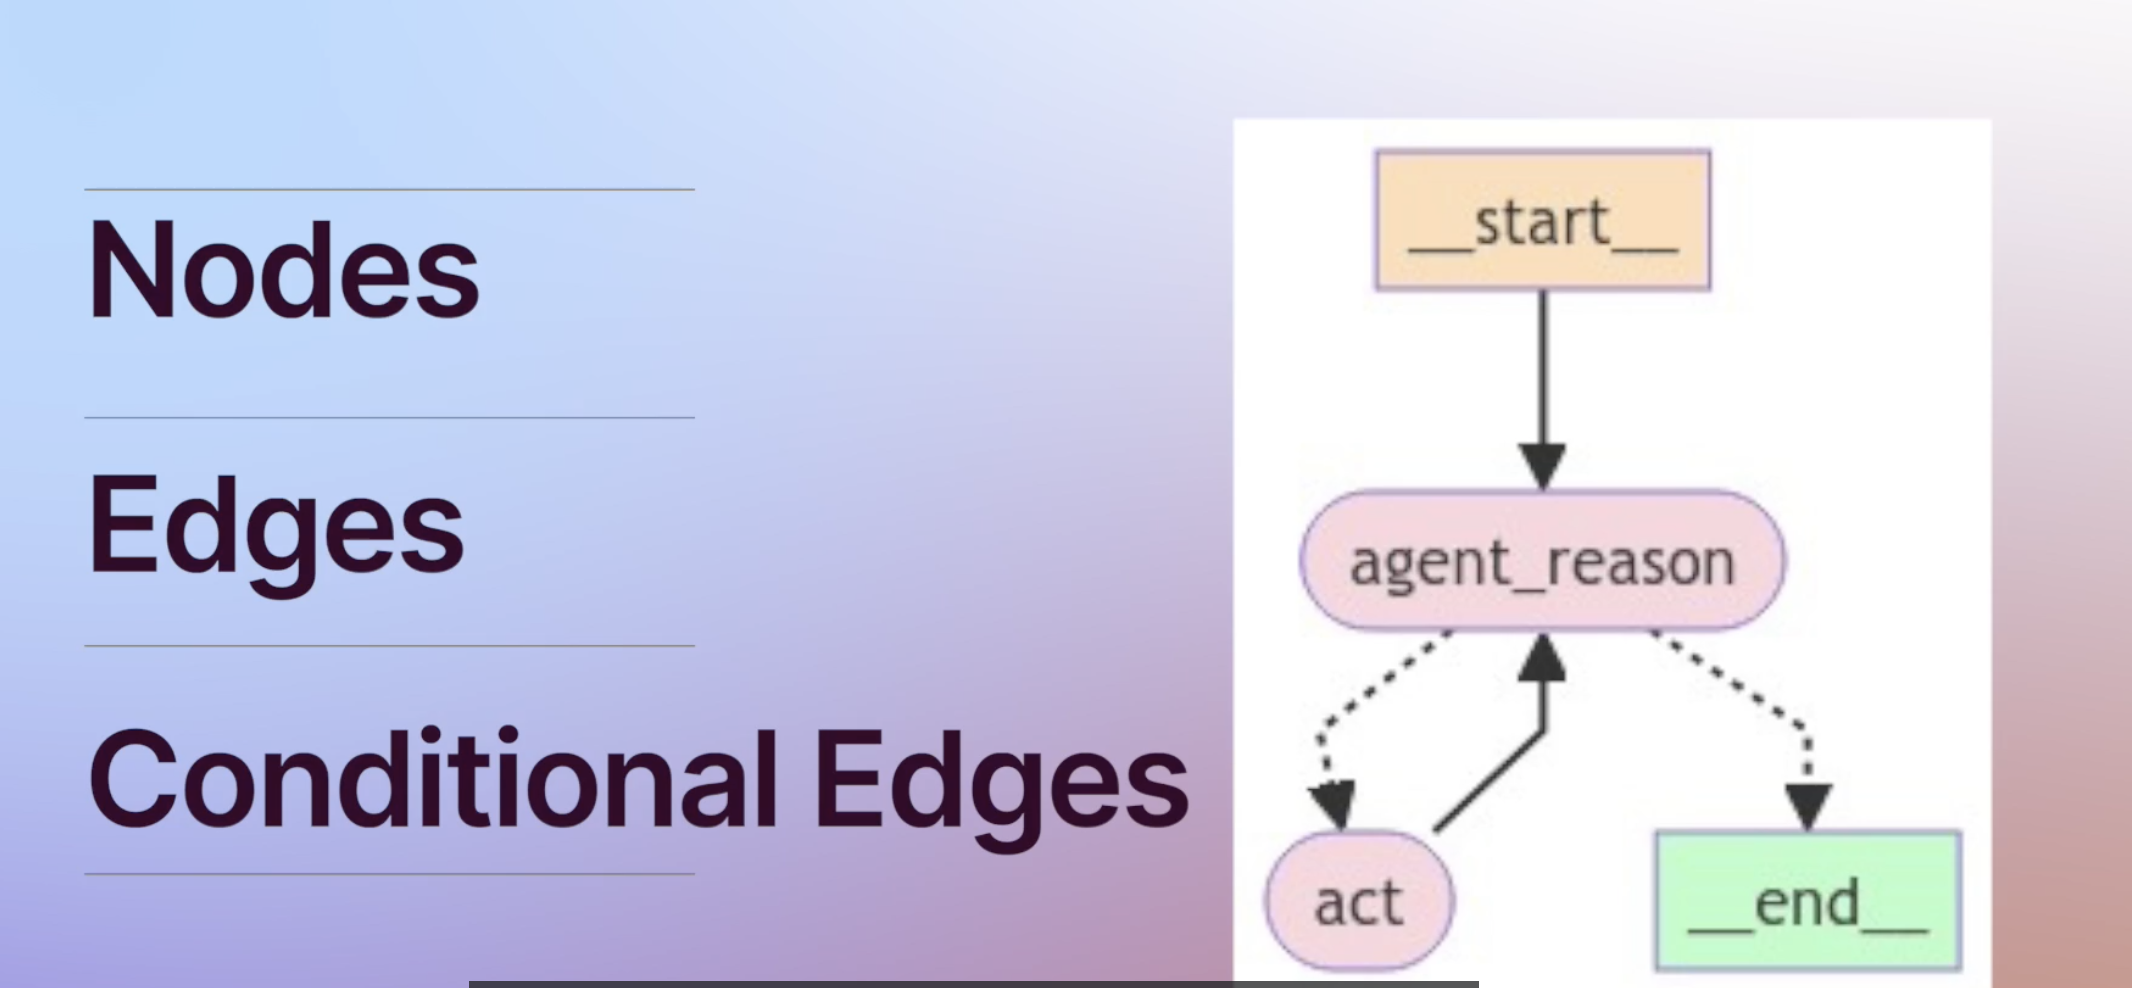

In [18]:
import random
from typing import TypedDict, List
from langgraph.graph import StateGraph, END

from IPython.display import Image
Image("image.png")

Three Langraph core components: 

- Nodes:Python functions (deterministic code, regular python code, it can be python code that calls an LLM, or it can be an LLM agent)
- Edges: connect the nodes with the execution graph execution.
- Conditional edges: Help to make decision whether to go to node A or node B.

1. setup: This node is defined to setup the default values for the game.
2. guess: This node guesses a number and appends it to the guesses list.
3. hint: This reads the last guess and compares it with target number. It also hints the bot if the number is lower or higher than the target value.

In [10]:
class AgentState(TypedDict):
    # It contains everything the game needs to remember, 
    # such as the player's guesses, number of attempts, the current range, and the target number.
    player_name: str
    guesses: List[int]
    attepts: int
    lower_bound: int
    upper_bound: int
    target_number: int

def setup(state: AgentState) -> AgentState:
   # Setting up the default setting for the game, also defining the target
    print("Welcome to the Number Guessing Game!")
    # state['lower_bound'] = 1
    # state['upper_bound'] = 20
    # state['target_number'] = random.randint(state['lower_bound'], state['upper_bound'])
    # state['guesses'] = []
    # state['attepts'] = 0
    return state

def guess(state: AgentState) -> AgentState:
    state['attepts'] += 1
    state['guesses'].append(random.randint(state['lower_bound'], state['upper_bound']))
    return state

def hint(state: AgentState) -> AgentState:
    last_guess = state['guesses'][-1]
    if last_guess < state['target_number']:
        print(f"Your guess of {last_guess} is too low.")
        state['lower_bound'] = last_guess + 1
    elif last_guess > state['target_number']:
        print(f"Your guess of {last_guess} is too high.")
        state['upper_bound'] = last_guess - 1
    else:
        print(f"Congratulations {state['player_name']}! You've guessed the number {state['target_number']} in {state['attepts']} attempts.")
    return state

def should_continue(state: AgentState) -> AgentState:
    if state["attepts"] < 7:
        print(f"You have {7 - state['attepts']} attempts left.")
        if state['guesses'][-1] == state['target_number']:
            return "Exit"
        else:
            return "Guess"
    print("No attempts left. Game over.")
    return "Exit"

In this game, we have to decide if we want to continue the guess, or exit. So how should I implement this?
By adding conditional edge. 

1. Each function becomes a node in LangGraph. Each node receives the current state, performs an action, updates the state, and returns it.
2. The hint node looks at the previous guess and the target number.
3. It then updates the range in the state so that the next guess can be more informed.

In [14]:
### Define a state graph

graph = StateGraph(AgentState)

graph.add_node("setup", setup)
graph.add_node("guess", guess)
graph.add_node("hint", hint)

graph.add_edge("setup", "guess")
graph.add_edge("guess", "hint")

graph.add_conditional_edges(
    "hint",
    should_continue,
    {
        "Guess": "guess",
        "Exit": END
    }
)

graph.set_entry_point("setup")

app = graph.compile()

In [13]:
app.invoke({"player_name": "Player1", "guesses": [], "attepts": 0, "lower_bound": 1, "upper_bound": 20, "target_number": 16})

Welcome to the Number Guessing Game!
Your guess of 14 is too low.
You have 6 attempts left.
Your guess of 15 is too low.
You have 5 attempts left.
Your guess of 19 is too high.
You have 4 attempts left.
Your guess of 17 is too high.
You have 3 attempts left.
Congratulations Player1! You've guessed the number 16 in 5 attempts.
You have 2 attempts left.


{'player_name': 'Player1',
 'guesses': [14, 15, 19, 17, 16],
 'attepts': 5,
 'lower_bound': 16,
 'upper_bound': 16,
 'target_number': 16}